[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/09_tuning.ipynb)

*Machine Learning from Scratch · Notebook 9 of 10*

# Tuning, Pipelines & Regularisation

Turning a model into a reliable system: hyper-parameter grids and grid search, validation and learning curves, choosing regularisation by CV, ColumnTransformer and pipelines, avoiding leakage, custom scorers and target transforms.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Tuning is adjusting the knobs on a radio, using a validation set so you don't fool yourself.

**What interviewers really test here:** Grid vs random search, nested CV, pipelines and preventing leakage.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Hyper-parameters and grid search *(Basics)*
- [ ] 2. Grid search, worked by hand *(Basics)*
- [ ] 3. Reading validation and learning curves *(Core)*
- [ ] 4. Tuning regularisation *(Core)*
- [ ] 5. Randomised search and log scales *(Core)*
- [ ] 6. From a curve to a decision *(Core)*
- [ ] 7. Pipelines and ColumnTransformer *(Advanced)*
- [ ] 8. Leakage: the mistake that flatters you *(Advanced)*
- [ ] 9. Nested cross-validation *(Advanced)*
- [ ] 10. A production-style pipeline on messy data *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Search strategies

| Method | How | Use when |
| --- | --- | --- |
| Grid search | every combination | few parameters, small grids |
| Randomised search | random samples from distributions | many parameters; only a few usually matter |
| Successive halving | many candidates on little data, keep the best, give them more | expensive models |
| Bayesian optimisation | a model of the score chooses the next try (Optuna) | each fit is costly |
| Built-in CV | RidgeCV, LassoCV, LogisticRegressionCV | fast paths for one parameter |

### Common hyper-parameters

| Model | Tune first |
| --- | --- |
| Linear / logistic | α or C (log scale) |
| k-NN | k, weights, metric |
| SVM (RBF) | C and γ together (log scale) |
| Decision tree | max\_depth, min\_samples\_leaf |
| Random forest | max\_features, min\_samples\_leaf; n\_estimators just needs to be large enough |
| Gradient boosting | learning\_rate with early stopping, max\_depth, subsample |
| Neural network | learning rate first, then size, regularisation, batch size |

### Keeping the estimate honest

- Split off the test set first and use it once.
- Put every fitted preprocessing step inside the pipeline, so each fold fits it on its training part only.
- The best CV score is optimistically biased, because it is the maximum of many noisy scores. **Nested CV** (an inner loop tunes, an outer loop scores) gives an unbiased estimate.
- Match the splitter to the data: stratified for classes, grouped for repeated subjects, time-based for time series.
- Compare mean ± std across folds. A difference smaller than the spread may be noise.

### sklearn's composition tools

| Tool | Purpose |
| --- | --- |
| Pipeline / make\_pipeline | steps in sequence |
| ColumnTransformer | different steps per column |
| FeatureUnion | several transformers side by side |
| TransformedTargetRegressor | fit on a transformed y, predict back on the original scale |
| FunctionTransformer | wrap any function as a step |
| make\_scorer | turn a metric into a CV scorer (scores are always "higher is better", so errors become negative) |
| joblib.dump / load | save and reload a fitted pipeline |

---
# Part 2: Lessons, step by step

## Lesson 1: Hyper-parameters and grid search

*Level: Basics*

Parameters are learned from the data; **hyper-parameters** are settings you choose before training: k in k-NN, tree depth, regularisation strength.



**Grid search** tries every combination and scores each with cross-validation:




1. List the candidate values (the **grid**).
2. For each combination, run k-fold CV and average the scores.
3. Keep the best combination, then refit it on all the training data.



The cost multiplies: 3 values × 2 values × 5 folds = 30 fits. For big grids, **randomised search** samples combinations and usually finds something nearly as good for far less work.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

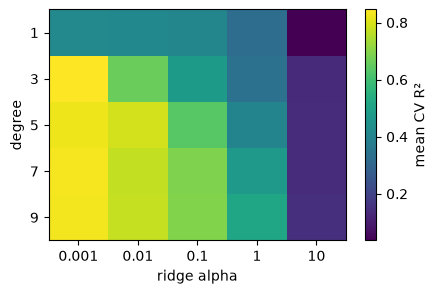

In [2]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
rng = np.random.default_rng(0)
X_DEMO = np.sort(rng.uniform(0, 1, 40)).reshape(-1, 1)
Y_DEMO = np.sin(2 * np.pi * X_DEMO[:, 0]) + rng.normal(0, 0.25, 40)


def search_heatmap():
    pipe = Pipeline([("poly", PolynomialFeatures()), ("ridge", Ridge())])
    degrees, alphas = [1, 3, 5, 7, 9], [0.001, 0.01, 0.1, 1, 10]
    grid = {"poly__degree": degrees, "ridge__alpha": alphas}
    cv = ShuffleSplit(n_splits=5, test_size=0.25, random_state=0)
    search = GridSearchCV(pipe, grid, cv=cv).fit(X_DEMO, Y_DEMO)
    scores = search.cv_results_["mean_test_score"].reshape(len(degrees), len(alphas))
    fig, ax = plt.subplots(figsize=(4.8, 3))
    image = ax.imshow(np.clip(scores, 0, 1), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(alphas)), alphas)
    ax.set_yticks(range(len(degrees)), degrees)
    ax.set_xlabel("ridge alpha")
    ax.set_ylabel("degree")
    fig.colorbar(image, label="mean CV R²")


search_heatmap()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q7](#q7), [Q3](#q3), [Q2](#q2), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 2: Grid search, worked by hand

*Level: Basics*

Choose k for k-NN with 3-fold CV. Suppose the fold accuracies come out like this:



| k | Fold 1 | Fold 2 | Fold 3 | Mean |
| --- | --- | --- | --- | --- |
| 1 | 0.80 | 0.70 | 0.75 | 0.75 |
| **5** | **0.85** | **0.80** | **0.78** | **0.81** |
| 15 | 0.70 | 0.72 | 0.71 | 0.71 |



1. k = 1 is noisy and overfits; k = 15 is too smooth and underfits. k = 5 wins.
2. **Refit** k = 5 on all the training data. That's `best_estimator_`.
3. Score it once on the test set.



**Cost:** 3 candidates × 3 folds = 9 fits, plus 1 refit = 10.



#### Common mistakes



- Reporting 0.81 as the expected performance. It's the best of several tries, so it's a little optimistic.
- Picking a winner by a difference smaller than the fold-to-fold spread.
- Stopping when the best value sits on the edge of the grid. Extend the grid and search again.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def grid_table():
    scores = {1: [0.80, 0.70, 0.75], 5: [0.85, 0.80, 0.78], 15: [0.70, 0.72, 0.71]}
    means = {k: round(float(np.mean(v)), 3) for k, v in scores.items()}
    spread = {k: round(float(np.std(v)), 3) for k, v in scores.items()}
    best_k = max(means, key=means.get)
    number_of_fits = len(scores) * 3 + 1


grid_table()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q2](#q2), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: Reading validation and learning curves

*Level: Core*

Two plots tell you what to do next.




- **Validation curve**: score against one hyper-parameter. On the simple side both scores are low (underfitting). On the complex side the training score stays high while the validation score drops (overfitting). Choose the peak of the validation score.
- **Learning curve**: score against the amount of training data. If the two lines have met at a low score, more data won't help, so use a richer model. If there's a big gap, more data or more regularisation will.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

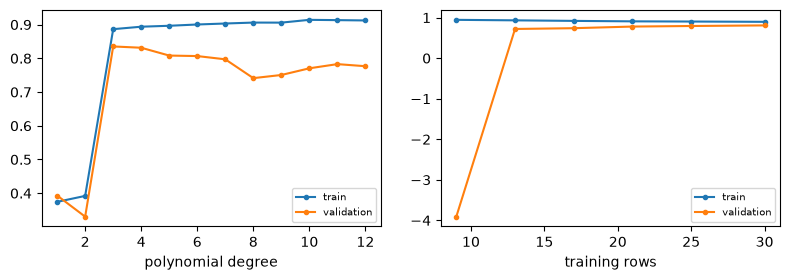

In [4]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
rng = np.random.default_rng(0)
X_DEMO = np.sort(rng.uniform(0, 1, 40)).reshape(-1, 1)
Y_DEMO = np.sin(2 * np.pi * X_DEMO[:, 0]) + rng.normal(0, 0.25, 40)


def curves():
    pipe = Pipeline([("poly", PolynomialFeatures()), ("lr", LinearRegression())])
    cv = ShuffleSplit(n_splits=10, test_size=0.25, random_state=0)
    degrees = np.arange(1, 13)
    tr, va = validation_curve(pipe, X_DEMO, Y_DEMO, param_name="poly__degree", param_range=degrees, cv=cv)
    pipe.set_params(poly__degree=5)
    sizes, tr2, va2 = learning_curve(pipe, X_DEMO, Y_DEMO, train_sizes=np.linspace(0.3, 1.0, 6), cv=cv)
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 2.9))
    left.plot(degrees, tr.mean(axis=1), "o-", markersize=3, label="train")
    left.plot(degrees, np.clip(va.mean(axis=1), -1, 1), "o-", markersize=3, label="validation")
    left.set_xlabel("polynomial degree")
    left.legend(fontsize=7)
    right.plot(sizes, tr2.mean(axis=1), "o-", markersize=3, label="train")
    right.plot(sizes, va2.mean(axis=1), "o-", markersize=3, label="validation")
    right.set_xlabel("training rows")
    right.legend(fontsize=7)
    fig.tight_layout()


curves()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Tuning regularisation

*Level: Core*

Regularisation strength is the most common thing to tune. sklearn has fast built-ins: `RidgeCV` computes leave-one-out errors in closed form, and `LassoCV` walks along a path of α values. For logistic regression, tune C (small C = strong penalty).



Search on a **log scale** (0.001, 0.01, 0.1, 1, 10): what matters is the order of magnitude. If the best value sits at the edge of your grid, extend the grid.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

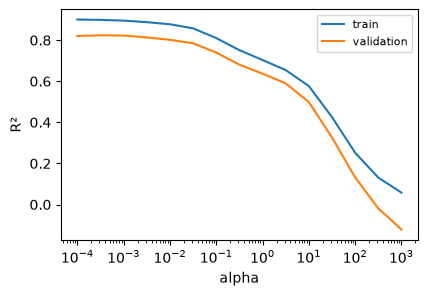

In [5]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
rng = np.random.default_rng(0)
X_DEMO = np.sort(rng.uniform(0, 1, 40)).reshape(-1, 1)
Y_DEMO = np.sin(2 * np.pi * X_DEMO[:, 0]) + rng.normal(0, 0.25, 40)


def alpha_sweep():
    pipe = make_pipeline(PolynomialFeatures(9), StandardScaler(), Ridge())
    alphas = np.logspace(-4, 3, 15)
    cv = ShuffleSplit(n_splits=10, test_size=0.25, random_state=0)
    tr, va = validation_curve(pipe, X_DEMO, Y_DEMO, param_name="ridge__alpha", param_range=alphas, cv=cv)
    fig, ax = plt.subplots(figsize=(4.6, 3))
    ax.semilogx(alphas, tr.mean(axis=1), label="train")
    ax.semilogx(alphas, va.mean(axis=1), label="validation")
    ax.set_xlabel("alpha")
    ax.set_ylabel("R²")
    ax.legend(fontsize=8)


alpha_sweep()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q18](#q18), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 5: Randomised search and log scales

*Level: Core*

Grids explode: 5 settings with 5 values each is 3,125 combinations, and 15,625 fits with 5-fold CV.



#### Why random often beats a grid



Usually only one or two settings matter much. Say you can afford 9 fits with two settings:



- **Grid (3 × 3):** tries just 3 values of the important setting.
- **Random:** tries 9 different values of it.



#### Search on the right scale



Going from α = 0.001 to 0.01 can matter as much as from 1 to 10. Sample these evenly on a **log** scale: learning rate, C, α, γ. Tree depth and leaf sizes are searched as plain integers.



#### A practical plan



1. Run a wide random search, 20–50 tries.
2. Look at which regions did well.
3. Run a narrow search there.
4. Stop when improvements fall below the fold-to-fold noise.



In sklearn: `RandomizedSearchCV(model, {"C": loguniform(1e-3, 1e3)}, n_iter=30)`. Optuna is a popular, smarter alternative.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

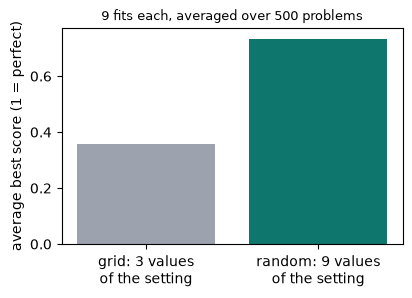

In [6]:
def grid_vs_random():
    r = np.random.default_rng(0)

    def best_score(values, peak):
        return np.exp(-(np.asarray(values) - peak) ** 2 / 0.01).max()

    grid_values = [0.0, 0.5, 1.0]
    averages = {"grid": [], "random": []}
    for trial in range(500):
        peak = r.uniform()
        averages["grid"].append(best_score(grid_values, peak))
        averages["random"].append(best_score(r.uniform(size=9), peak))
    grid_mean = float(np.mean(averages["grid"]))
    random_mean = float(np.mean(averages["random"]))
    fig, ax = plt.subplots(figsize=(4.4, 2.8))
    ax.bar(["grid: 3 values\nof the setting", "random: 9 values\nof the setting"], [grid_mean, random_mean], color=["#9ca3af", "#0f766e"])
    ax.set_ylabel("average best score (1 = perfect)")
    ax.set_title("9 fits each, averaged over 500 problems", fontsize=9)


grid_vs_random()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. best\_score() returns 0.15322461237439208
2. best\_score() returns 0.912136078497261
3. best\_score() returns 0.03367527626135572
4. best\_score() returns 0.8414352167605219
5. best\_score() returns 0.9229313932837241
6. best\_score() returns 0.3981599956903459
7. best\_score() returns 0.028689702276842664
8. best\_score() returns 0.8965736857248655
9. best\_score() returns 0.5995045778544783
10. best\_score() returns 0.9494729874318244
11. best\_score() returns 0.010751467012733837
12. best\_score() returns 0.9915242841809726
13. best\_score() returns 0.4021077754560917
14. best\_score() returns 0.8559318284470834
15. best\_score() returns 0.18883314596961917
16. best\_score() returns 0.9921196461193139
17. best\_score() returns 0.0028241968955386746
18. best\_score() returns 0.9473996346755821
19. best\_score() returns 0.590533677007243
20. best\_score() returns 0.9150998675651831
21. best\_score() returns 0.9607430155506945

</details>


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 6: From a curve to a decision

*Level: Core*

Read your train and validation scores, then act:



| Train | Validation | Diagnosis | Next step |
| --- | --- | --- | --- |
| 0.65 | 0.63 | underfitting | more features, a more flexible model, less regularisation |
| 0.99 | 0.72 | overfitting | more data, more regularisation, a simpler model, ensembling |
| 0.86 | 0.84 | healthy | check it against the goal; analyse the errors |
| 0.86 | 0.97 | suspicious | check for leakage or an unlucky split |



#### Error analysis usually beats more tuning



Take the 50 worst predictions and read them. You'll often find mislabelled rows, a missing feature, or one group where the model fails. Fixing those typically gains far more than another grid search.



#### The order of work



1. Fix the data and the validation scheme.
2. Add better features.
3. Try a better model family.
4. Only then tune hyper-parameters.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def diagnose():
    def diagnosis(train, val):
        if val > train + 0.03:
            return "suspicious"
        if train < 0.75:
            return "underfitting"
        if train - val > 0.1:
            return "overfitting"
        return "healthy"

    results = {pair: diagnosis(*pair) for pair in [(0.65, 0.63), (0.99, 0.72), (0.86, 0.84), (0.86, 0.97)]}


diagnose()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. diagnosis() returns 'underfitting'
2. diagnosis() returns 'overfitting'
3. diagnosis() returns 'healthy'
4. diagnosis() returns 'suspicious'
5. diagnose() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 7: Pipelines and ColumnTransformer

*Level: Advanced*

Real tables mix numbers, categories and gaps. A **ColumnTransformer** applies different steps to different columns, and a **Pipeline** chains those steps with the model:



```python
num = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
prep = ColumnTransformer([("num", num, ["age", "income"]), ("cat", cat, ["city"])])
model = make_pipeline(prep, LogisticRegression())
```



The whole object fits, predicts, cross-validates and can be saved as one unit, so training and production run the same steps. Tune nested settings with step names and a double underscore: `logisticregression__C`.



Useful extras: `TransformedTargetRegressor` (model a log target), `FeatureUnion` (build features side by side), `add_indicator=True` (keep a flag for what was missing).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


def column_transformer_demo():
    rows = np.array([[10, "red"], [20, "blue"], [30, "red"], [40, "green"]], dtype=object)
    ct = ColumnTransformer([("num", StandardScaler(), [0]), ("cat", OneHotEncoder(sparse_output=False), [1])])
    table = ct.fit_transform(rows).astype(float).round(2)
    columns = ct.get_feature_names_out().tolist()


column_transformer_demo()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q15](#q15), [Q5](#q5), [Q6](#q6), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 8: Leakage: the mistake that flatters you

*Level: Advanced*

If any preprocessing step sees validation rows, your score is too good to be true. A striking case: take **pure noise** with 200 features, choose the 5 most correlated with the target using all the data, then cross-validate. The score looks positive even though there is nothing to find.



Put the selection inside the pipeline and it is redone on each training part only. The score falls to where it belongs, at or below zero.



**Rule:** everything learned from data (scalers, imputers, encoders, feature selection, PCA) goes inside the pipeline. And after tuning, use a separate test set or nested CV, because the best CV score was picked from many tries and is slightly optimistic.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

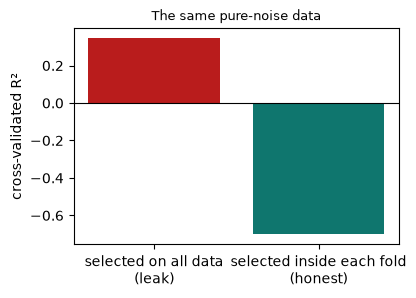

In [9]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge


def leakage_bars():
    from sklearn.feature_selection import SelectKBest, f_regression
    from sklearn.model_selection import cross_val_score
    r = np.random.RandomState(0)
    X, y = r.normal(size=(30, 200)), r.normal(size=30)
    leaked = SelectKBest(f_regression, k=5).fit_transform(X, y)
    leaky = cross_val_score(LinearRegression(), leaked, y, cv=KFold(5)).mean()
    honest = cross_val_score(make_pipeline(SelectKBest(f_regression, k=5), LinearRegression()), X, y, cv=KFold(5)).mean()
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.bar(["selected on all data\n(leak)", "selected inside each fold\n(honest)"], [leaky, honest], color=["#b91c1c", "#0f766e"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("cross-validated R²")
    ax.set_title("The same pure-noise data", fontsize=9)


leakage_bars()

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 9: Nested cross-validation

*Level: Advanced*

If you choose settings using CV, then report that same CV score, you've measured the model on data that helped choose it. With little data or many candidates, the score is too high.



#### The structure



- **Outer loop** (say 5 folds): holds out data to measure performance.
- **Inner loop** (say 3 folds), inside each outer training part: picks settings.



Total fits = outer × candidates × inner, so 5 × 10 × 3 = 150, plus refits.



#### Important



Nested CV estimates how good the **whole tuning process** is. It doesn't give you one final model. For that, run the search once on all the data.



The demo uses pure-noise data, where nothing can truly beat 50%. The best inner score looks better than chance because it picks the luckiest candidate. Nested CV gives a much lower score, and any gap from 50% is just noise. With plenty of data and a real test set, you can skip nesting.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

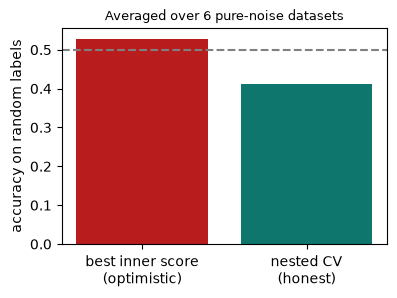

In [10]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve


def nested_demo():
    from sklearn.model_selection import cross_val_score
    from sklearn.svm import SVC
    grid = {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}
    plain_scores, nested_scores = [], []
    for seed in range(6):
        r = np.random.RandomState(seed)
        X, y = r.normal(size=(40, 20)), r.randint(0, 2, 40)
        search = GridSearchCV(SVC(), grid, cv=KFold(3, shuffle=True, random_state=seed))
        plain_scores.append(search.fit(X, y).best_score_)
        nested_scores.append(cross_val_score(search, X, y, cv=KFold(3, shuffle=True, random_state=seed + 100)).mean())
    plain = float(np.mean(plain_scores))
    nested = float(np.mean(nested_scores))
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.bar(["best inner score\n(optimistic)", "nested CV\n(honest)"], [plain, nested], color=["#b91c1c", "#0f766e"])
    ax.axhline(0.5, ls="--", color="gray")
    ax.set_ylabel("accuracy on random labels")
    ax.set_title("Averaged over 6 pure-noise datasets", fontsize=9)


nested_demo()

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 10: A production-style pipeline on messy data

*Level: Advanced*

Real tables mix types and contain gaps. The demo builds the whole thing:



1. Numbers: median imputation, then scaling.
2. Categories: most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"`, so a new city in production won't crash the model.
3. A model, tuned by grid search using the name `logisticregression__C`.
4. Saving: `joblib.dump(search.best_estimator_, "model.joblib")`.



#### Before you deploy



- **Same steps everywhere:** the saved pipeline guarantees training and serving match.
- **Versions:** a saved model should be loaded with the same scikit-learn version.
- **Monitoring:** check input distributions and scores over time; the world changes (**drift**).
- **Security:** only load model files you trust, since loading can run code.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
from sklearn.model_selection import GridSearchCV, KFold, ShuffleSplit, validation_curve, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


def messy_pipeline():
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    r = np.random.default_rng(0)
    n = 120
    age = r.uniform(20, 60, n)
    city = r.choice(["Pune", "Delhi", "Goa"], n)
    bought = ((age > 40) ^ (r.uniform(size=n) < 0.15)).astype(int)
    df = pd.DataFrame({"age": age, "city": city})
    df.loc[::9, "age"] = np.nan
    df.loc[::13, "city"] = None
    numbers = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    categories = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
    prep = ColumnTransformer([("num", numbers, ["age"]), ("cat", categories, ["city"])])
    pipe = make_pipeline(prep, LogisticRegression())
    search = GridSearchCV(pipe, {"logisticregression__C": [0.01, 1, 100]}, cv=3).fit(df, bought)
    best = search.best_params_
    score = round(search.best_score_, 3)
    new_row = pd.DataFrame({"age": [55.0], "city": ["Mumbai"]})
    probability_for_unseen_city = round(search.predict_proba(new_row)[0, 1], 3)


messy_pipeline()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q6](#q6). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
from sklearn.model_selection import (ParameterGrid, GridSearchCV, KFold, cross_val_score, cross_validate,
                                     validation_curve, learning_curve)

from sklearn.neighbors import KNeighborsClassifier

import math

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, LassoCV, LogisticRegression

from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer

from sklearn.pipeline import make_pipeline, Pipeline, FeatureUnion

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor


<a id="q1"></a>
### Q1. Expand a Parameter Grid

🟢 Warm-up · *Every combination*

Given a dict of parameter lists, return every combination as a dict (keys in sorted order, last key changing fastest).

**Examples**

- `grid = {'k': [1, 3], 'weights': ['uniform', 'distance']}` → `[{'k': 1, 'weights': 'uniform'}, {'k': 1, 'weights': 'distance'}, {'k': 3, 'weights': 'uniform'}, {'k': 3, 'weights': 'distance'}]`
- `grid = {'alpha': [0.1, 1, 10]}` → `[{'alpha': 0.1}, {'alpha': 1}, {'alpha': 10}]`

In [ ]:
from itertools import product

def expand(grid):
    """
    Given a dict of parameter lists, return every combination as a dict (keys in
    sorted order, last key changing fastest).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expand, [
    (({'k': [1, 3], 'weights': ['uniform', 'distance']},), [{'k': 1, 'weights': 'uniform'}, {'k': 1, 'weights': 'distance'}, {'k': 3, 'weights': 'uniform'}, {'k': 3, 'weights': 'distance'}]),
    (({'alpha': [0.1, 1, 10]},), [{'alpha': 0.1}, {'alpha': 1}, {'alpha': 10}]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`itertools.product` over the sorted keys' value lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`list(ParameterGrid(grid))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `itertools.product` over the sorted keys' value lists.

```python
def expand(grid):
    keys = sorted(grid)
    return [dict(zip(keys, combo)) for combo in product(*(grid[k] for k in keys))]
```

**Cost:** O(Π sizes) time, O(Π sizes) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `list(ParameterGrid(grid))`.

```python
def expand(grid):
    return list(ParameterGrid(grid))
```

**Cost:** O(Π sizes) time, O(Π sizes) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `itertools.product` over the sorted keys' value lists. That costs O(Π sizes) time and O(Π sizes) space."

"I can do better: `list(ParameterGrid(grid))`. That's O(Π sizes) time and O(Π sizes) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/expand-a-parameter-grid)

<a id="q2"></a>
### Q2. Mean and Spread of CV Scores

🟢 Warm-up · *Report mean ± std*

Return (mean, std) of the 3-fold accuracies of 3-NN, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1]` → `(0.75, 0.0)`

In [ ]:
def cv_summary(X, y):
    """
    Return (mean, std) of the 3-fold accuracies of 3-NN, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cv_summary, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1]), (0.75, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Collect fold scores by hand; population std.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cross_val_score(...)` then `.mean()`, `.std()`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Collect fold scores by hand; population std.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def cv_summary(X, y):
    scores = []
    for test in folds(len(X), 3):
        train = [i for i in range(len(X)) if i not in test]
        pred = KNeighborsClassifier(n_neighbors=3).fit([X[i] for i in train], [y[i] for i in train]).predict([X[i] for i in test])
        scores.append(sum(p == y[i] for p, i in zip(pred, test)) / len(test))
    mean = sum(scores) / len(scores)
    std = math.sqrt(sum((s - mean) ** 2 for s in scores) / len(scores))
    return (round(mean, 4), round(std, 4))
```

**Cost:** O(folds·fit) time, O(folds) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cross_val_score(...)` then `.mean()`, `.std()`.

```python
def cv_summary(X, y):
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=3), X, y, cv=KFold(3))
    return (round(scores.mean(), 4), round(scores.std(), 4))
```

**Cost:** O(folds·fit) time, O(folds) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Collect fold scores by hand; population std. That costs O(folds·fit) time and O(folds) space."

"I can do better: `cross_val_score(...)` then `.mean()`, `.std()`. That's O(folds·fit) time and O(folds) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/mean-and-spread-of-cv-scores)

<a id="q3"></a>
### Q3. How Many Models Does a Grid Search Train?

🟢 Warm-up · *The cost of tuning*

Return the number of fits for a grid search over the given grid with k-fold CV (not counting the final refit).

**Examples**

- `grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}, k = 5` → `30`
- `grid = {'alpha': [1, 2, 3, 4]}, k = 3` → `12`

In [ ]:
def n_fits(grid, k):
    """
    Return the number of fits for a grid search over the given grid with k-fold
    CV (not counting the final refit).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(n_fits, [
    (({'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}, 5), 30),
    (({'alpha': [1, 2, 3, 4]}, 3), 12),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the list sizes, then by k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`len(ParameterGrid(grid)) * k`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Multiply the list sizes, then by k.

```python
def n_fits(grid, k):
    combos = 1
    for values in grid.values():
        combos *= len(values)
    return combos * k
```

**Cost:** O(params) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `len(ParameterGrid(grid)) * k`.

```python
def n_fits(grid, k):
    return len(ParameterGrid(grid)) * k
```

**Cost:** O(combos) time, O(combos) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the list sizes, then by k. That costs O(params) time and O(1) space."

"I can do better: `len(ParameterGrid(grid)) * k`. That's O(combos) time and O(combos) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/how-many-models-does-a-grid-search-train)

<a id="q4"></a>
### Q4. A Custom Scorer

🟢 Warm-up · *Negative MAE*

Return the 3-fold (contiguous) cross-validated scores of a straight-line fit using negative mean absolute error, rounded to 4 decimals.

**Examples**

- `X = [[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], y = [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3]` → `[-22.7452, -10.3969, -21.4405]`

In [ ]:
from sklearn.metrics import make_scorer, mean_absolute_error

def neg_mae_cv(X, y):
    """
    Return the 3-fold (contiguous) cross-validated scores of a straight-line fit
    using negative mean absolute error, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(neg_mae_cv, [
    (([[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3]), [-22.7452, -10.3969, -21.4405]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over folds, fit, compute −MAE.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`make_scorer(mean_absolute_error, greater_is_better=False)` in `cross_val_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over folds, fit, compute −MAE.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def neg_mae_cv(X, y):
    out = []
    for test in folds(len(X), 3):
        train = [i for i in range(len(X)) if i not in test]
        slope, intercept = np.polyfit([X[i][0] for i in train], [y[i] for i in train], 1)
        errors = [abs(y[i] - (slope * X[i][0] + intercept)) for i in test]
        out.append(round(-sum(errors) / len(errors), 4))
    return out
```

**Cost:** O(folds·n) time, O(folds) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `make_scorer(mean_absolute_error, greater_is_better=False)` in `cross_val_score`.

```python
def neg_mae_cv(X, y):
    scorer = make_scorer(mean_absolute_error, greater_is_better=False)
    return cross_val_score(LinearRegression(), X, y, cv=KFold(3), scoring=scorer).round(4)
```

**Cost:** O(folds·n) time, O(folds) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over folds, fit, compute −MAE. That costs O(folds·n) time and O(folds) space."

"I can do better: `make_scorer(mean_absolute_error, greater_is_better=False)` in `cross_val_score`. That's O(folds·n) time and O(folds) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/a-custom-scorer)

<a id="q5"></a>
### Q5. Combine Feature Sets

🟢 Warm-up · *FeatureUnion*

For one-column X, return rows [x, x², log(1 + x)] — three transformers applied side by side. Round to 4 decimals.

**Examples**

- `X = [[0], [1], [3]]` → `[[0.0, 0.0, 0.0], [1.0, 1.0, 0.6931], [3.0, 9.0, 1.3863]]`

In [ ]:
def union(X):
    """
    For one-column X, return rows [x, x², log(1 + x)] — three transformers
    applied side by side. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(union, [
    (([[0], [1], [3]],), [[0.0, 0.0, 0.0], [1.0, 1.0, 0.6931], [3.0, 9.0, 1.3863]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the three columns by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`FeatureUnion` of three `FunctionTransformer`s.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute the three columns by hand.

```python
def union(X):
    return [[float(r[0]), float(r[0] ** 2), round(math.log1p(r[0]), 4)] for r in X]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `FeatureUnion` of three `FunctionTransformer`s.

```python
def union(X):
    fu = FeatureUnion([("x", FunctionTransformer()), ("sq", FunctionTransformer(np.square)), ("log", FunctionTransformer(np.log1p))])
    return fu.fit_transform(np.array(X, dtype=float)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the three columns by hand. That costs O(n) time and O(n) space."

"I can do better: `FeatureUnion` of three `FunctionTransformer`s. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/combine-feature-sets)

<a id="q6"></a>
### Q6. Missing-Value Indicator Columns

🟢 Warm-up · *Keep the fact that it was missing*

Mean-impute each column and append a 0/1 column for every column that had missing values. None = missing. Round to 4 decimals.

**Examples**

- `rows = [[1, 5], [None, 6], [3, 7]]` → `[[1.0, 5.0, 0.0], [2.0, 6.0, 1.0], [3.0, 7.0, 0.0]]`

In [ ]:
def impute_with_flags(rows):
    """
    Mean-impute each column and append a 0/1 column for every column that had
    missing values. None = missing. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(impute_with_flags, [
    (([[1, 5], [None, 6], [3, 7]],), [[1.0, 5.0, 0.0], [2.0, 6.0, 1.0], [3.0, 7.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Impute by hand; for columns with gaps, add the indicator.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`SimpleImputer(add_indicator=True)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Impute by hand; for columns with gaps, add the indicator.

```python
def impute_with_flags(rows):
    d = len(rows[0])
    means = [sum(r[j] for r in rows if r[j] is not None) / sum(1 for r in rows if r[j] is not None) for j in range(d)]
    gappy = [j for j in range(d) if any(r[j] is None for r in rows)]
    out = []
    for r in rows:
        filled = [round(float(means[j] if r[j] is None else r[j]), 4) for j in range(d)]
        out.append(filled + [1.0 if r[j] is None else 0.0 for j in gappy])
    return out
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `SimpleImputer(add_indicator=True)`.

```python
def impute_with_flags(rows):
    A = np.array([[np.nan if v is None else v for v in r] for r in rows], dtype=float)
    return SimpleImputer(add_indicator=True).fit_transform(A).round(4)
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Impute by hand; for columns with gaps, add the indicator. That costs O(n·d) time and O(n·d) space."

"I can do better: `SimpleImputer(add_indicator=True)`. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/missing-value-indicator-columns)

<a id="q7"></a>
### Q7. Grid Search by Hand

🟡 Interview standard · *Pick k with cross-validation*

For each k in ks, compute the mean 3-fold accuracy (contiguous folds) of k-NN. Return (best k, its mean accuracy rounded to 4 decimals); smallest k wins ties.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], ks = [1, 3, 5]` → `(5, 0.8333)`

In [ ]:
def grid_search_knn(X, y, ks):
    """
    For each k in ks, compute the mean 3-fold accuracy (contiguous folds) of
    k-NN. Return (best k, its mean accuracy rounded to 4 decimals); smallest k
    wins ties.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(grid_search_knn, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], [1, 3, 5]), (5, 0.8333)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two loops: over k, over folds; fit on the other folds, score on this one.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GridSearchCV(KNeighborsClassifier(), {'n_neighbors': ks}, cv=KFold(3))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Two loops: over k, over folds; fit on the other folds, score on this one.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def grid_search_knn(X, y, ks):
    best = (None, -1)
    for k in ks:
        scores = []
        for test in folds(len(X), 3):
            train = [i for i in range(len(X)) if i not in test]
            model = KNeighborsClassifier(n_neighbors=k).fit([X[i] for i in train], [y[i] for i in train])
            pred = model.predict([X[i] for i in test])
            scores.append(sum(p == y[i] for p, i in zip(pred, test)) / len(test))
        mean = sum(scores) / len(scores)
        if mean > best[1] + 1e-12:
            best = (k, mean)
    return (best[0], round(best[1], 4))
```

**Cost:** O(K·folds·fit) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GridSearchCV(KNeighborsClassifier(), {'n_neighbors': ks}, cv=KFold(3))`.

```python
def grid_search_knn(X, y, ks):
    search = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": ks}, cv=KFold(3)).fit(X, y)
    return (search.best_params_["n_neighbors"], round(search.best_score_, 4))
```

**Cost:** O(K·folds·fit) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two loops: over k, over folds; fit on the other folds, score on this one. That costs O(K·folds·fit) time and O(n) space."

"I can do better: `GridSearchCV(KNeighborsClassifier(), {'n_neighbors': ks}, cv=KFold(3))`. That's O(K·folds·fit) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/grid-search-by-hand)

<a id="q8"></a>
### Q8. Validation Curve

🟡 Interview standard · *Train vs validation score per setting*

For polynomial degree d in degrees, return (mean train R², mean validation R²) over 5 contiguous folds, rounded to 3 decimals.

**Examples**

- `X = [[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], y = [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], degrees = [1, 2, 3]` → `[(0.938, -685.756), (1.0, 0.457), (1.0, -0.126)]`

In [ ]:
def val_curve(X, y, degrees):
    """
    For polynomial degree d in degrees, return (mean train R², mean validation
    R²) over 5 contiguous folds, rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(val_curve, [
    (([[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], [1, 2, 3]), [(0.938, -685.756), (1.0, 0.457), (1.0, -0.126)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over degrees and folds; fit polynomial regression on train folds, score both parts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`validation_curve(pipe, X, y, param_name='poly__degree', param_range=…, cv=KFold(5))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loops over degrees and folds; fit polynomial regression on train folds, score both parts.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def val_curve(X, y, degrees):
    out = []
    for d in degrees:
        tr_scores, va_scores = [], []
        for test in folds(len(X), 5):
            train = [i for i in range(len(X)) if i not in test]
            coeffs = np.polyfit([X[i][0] for i in train], [y[i] for i in train], d)

            def r2(idx):
                actual = np.array([y[i] for i in idx])
                pred = np.polyval(coeffs, [X[i][0] for i in idx])
                return 1 - ((actual - pred) ** 2).sum() / ((actual - actual.mean()) ** 2).sum()

            tr_scores.append(r2(train))
            va_scores.append(r2(test))
        out.append((round(float(np.mean(tr_scores)), 3), round(float(np.mean(va_scores)), 3)))
    return out
```

**Cost:** O(D·folds·fit) time, O(D) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `validation_curve(pipe, X, y, param_name='poly__degree', param_range=…, cv=KFold(5))`.

```python
def val_curve(X, y, degrees):
    pipe = Pipeline([("poly", PolynomialFeatures()), ("lr", LinearRegression())])
    tr, va = validation_curve(pipe, X, y, param_name="poly__degree", param_range=degrees, cv=KFold(5))
    return [(round(a, 3), round(b, 3)) for a, b in zip(tr.mean(axis=1), va.mean(axis=1))]
```

**Cost:** O(D·folds·fit) time, O(D) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over degrees and folds; fit polynomial regression on train folds, score both parts. That costs O(D·folds·fit) time and O(D) space."

"I can do better: `validation_curve(pipe, X, y, param_name='poly__degree', param_range=…, cv=KFold(5))`. That's O(D·folds·fit) time and O(D) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/validation-curve)

<a id="q9"></a>
### Q9. Learning Curve

🟡 Interview standard · *Would more data help?*

Using 3-NN and 3 contiguous folds, for each training size n (the first n rows of each fold's training part), return the mean validation accuracy, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], sizes = [4, 6, 8]` → `[0.5, 0.8333, 0.75]`

In [ ]:
def learn_curve(X, y, sizes):
    """
    Using 3-NN and 3 contiguous folds, for each training size n (the first n
    rows of each fold's training part), return the mean validation accuracy,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(learn_curve, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], [4, 6, 8]), [0.5, 0.8333, 0.75]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over sizes and folds: truncate the training indices, fit, score.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`learning_curve(model, X, y, train_sizes=…, cv=KFold(3))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loops over sizes and folds: truncate the training indices, fit, score.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def learn_curve(X, y, sizes):
    out = []
    for n in sizes:
        scores = []
        for test in folds(len(X), 3):
            train = [i for i in range(len(X)) if i not in test][:n]
            pred = KNeighborsClassifier(n_neighbors=3).fit([X[i] for i in train], [y[i] for i in train]).predict([X[i] for i in test])
            scores.append(sum(p == y[i] for p, i in zip(pred, test)) / len(test))
        out.append(round(sum(scores) / len(scores), 4))
    return out
```

**Cost:** O(S·folds·fit) time, O(S) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `learning_curve(model, X, y, train_sizes=…, cv=KFold(3))`.

```python
def learn_curve(X, y, sizes):
    _, _, va = learning_curve(KNeighborsClassifier(n_neighbors=3), X, y, train_sizes=sizes, cv=KFold(3))
    return va.mean(axis=1).round(4)
```

**Cost:** O(S·folds·fit) time, O(S) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over sizes and folds: truncate the training indices, fit, score. That costs O(S·folds·fit) time and O(S) space."

"I can do better: `learning_curve(model, X, y, train_sizes=…, cv=KFold(3))`. That's O(S·folds·fit) time and O(S) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/learning-curve)

<a id="q10"></a>
### Q10. Choose the Polynomial Degree by CV

🟡 Interview standard · *Grid search over a pipeline step*

Return the degree in degrees with the best mean 5-fold (contiguous) R².

**Examples**

- `X = [[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], y = [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], degrees = [1, 2, 3, 4]` → `2`

In [ ]:
def best_degree(X, y, degrees):
    """
    Return the degree in degrees with the best mean 5-fold (contiguous) R².
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_degree, [
    (([[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], [1, 2, 3, 4]), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Same loops as the validation curve, keep the best validation score.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GridSearchCV(pipe, {'poly__degree': degrees}, cv=KFold(5))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Same loops as the validation curve, keep the best validation score.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def best_degree(X, y, degrees):
    best = (None, -math.inf)
    for d in degrees:
        scores = []
        for test in folds(len(X), 5):
            train = [i for i in range(len(X)) if i not in test]
            coeffs = np.polyfit([X[i][0] for i in train], [y[i] for i in train], d)
            actual = np.array([y[i] for i in test])
            pred = np.polyval(coeffs, [X[i][0] for i in test])
            scores.append(1 - ((actual - pred) ** 2).sum() / ((actual - actual.mean()) ** 2).sum())
        if np.mean(scores) > best[1] + 1e-12:
            best = (d, np.mean(scores))
    return best[0]
```

**Cost:** O(D·folds·fit) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GridSearchCV(pipe, {'poly__degree': degrees}, cv=KFold(5))`.

```python
def best_degree(X, y, degrees):
    pipe = Pipeline([("poly", PolynomialFeatures()), ("lr", LinearRegression())])
    return GridSearchCV(pipe, {"poly__degree": degrees}, cv=KFold(5)).fit(X, y).best_params_["poly__degree"]
```

**Cost:** O(D·folds·fit) time, O(D) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Same loops as the validation curve, keep the best validation score. That costs O(D·folds·fit) time and O(1) space."

"I can do better: `GridSearchCV(pipe, {'poly__degree': degrees}, cv=KFold(5))`. That's O(D·folds·fit) time and O(D) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/choose-the-polynomial-degree-by-cv)

<a id="q11"></a>
### Q11. Ridge With Several Features

🟡 Interview standard · *Closed form vs library*

Fit Ridge(alpha) on centred data: w = (XcᵀXc + αI)⁻¹Xcᵀyc, intercept = ȳ − x̄·w. Return [intercept, w…] rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 4], [4, 3], [5, 5]], y = [5, 4, 10, 9, 13], alpha = 1.0` → `[1.2526, 0.8246, 1.4912]`

In [ ]:
def ridge_multi(X, y, alpha):
    """
    Fit Ridge(alpha) on centred data: w = (XcᵀXc + αI)⁻¹Xcᵀyc, intercept = ȳ −
    x̄·w. Return [intercept, w…] rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ridge_multi, [
    (([[1, 2], [2, 1], [3, 4], [4, 3], [5, 5]], [5, 4, 10, 9, 13], 1.0), [1.2526, 0.8246, 1.4912]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre, solve the regularised normal equations with NumPy.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Ridge(alpha=α)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre, solve the regularised normal equations with NumPy.

```python
def ridge_multi(X, y, alpha):
    A, t = np.array(X, dtype=float), np.array(y, dtype=float)
    mx, my = A.mean(axis=0), t.mean()
    Ac = A - mx
    w = np.linalg.solve(Ac.T @ Ac + alpha * np.eye(A.shape[1]), Ac.T @ (t - my))
    return np.concatenate([[my - mx @ w], w]).round(4)
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Ridge(alpha=α)`.

```python
def ridge_multi(X, y, alpha):
    model = Ridge(alpha=alpha).fit(X, y)
    return np.concatenate([[model.intercept_], model.coef_]).round(4)
```

**Cost:** O(n·d²) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre, solve the regularised normal equations with NumPy. That costs O(n·d² + d³) time and O(d²) space."

"I can do better: `Ridge(alpha=α)`. That's O(n·d²) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/ridge-with-several-features)

<a id="q12"></a>
### Q12. ColumnTransformer: Numbers and Categories

🟡 Interview standard · *Different steps per column*

Columns 0 is numeric, column 1 is a category. Standardise column 0 and one-hot column 1 (sorted categories). Return the transformed rows, rounded to 4 decimals.

**Examples**

- `rows = [[10, 'red'], [20, 'blue'], [30, 'red'], [40, 'green']]` → `[[-1.3416, 0.0, 0.0, 1.0], [-0.4472, 1.0, 0.0, 0.0], [0.4472, 0.0, 0.0, 1.0], [1.3416, 0.0, 1.0, 0.0]]`

In [ ]:
def column_transform(rows):
    """
    Columns 0 is numeric, column 1 is a category. Standardise column 0 and one-
    hot column 1 (sorted categories). Return the transformed rows, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(column_transform, [
    (([[10, 'red'], [20, 'blue'], [30, 'red'], [40, 'green']],), [[-1.3416, 0.0, 0.0, 1.0], [-0.4472, 1.0, 0.0, 0.0], [0.4472, 0.0, 0.0, 1.0], [1.3416, 0.0, 1.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mean/std of the numbers, sorted categories for the one-hot columns, build each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ColumnTransformer([('num', StandardScaler(), [0]), ('cat', OneHotEncoder(), [1])])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Mean/std of the numbers, sorted categories for the one-hot columns, build each row.

```python
def column_transform(rows):
    nums = [r[0] for r in rows]
    mean = sum(nums) / len(nums)
    std = math.sqrt(sum((v - mean) ** 2 for v in nums) / len(nums))
    cats = sorted(set(r[1] for r in rows))
    return [[round((r[0] - mean) / std, 4)] + [1.0 if r[1] == c else 0.0 for c in cats] for r in rows]
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `ColumnTransformer([('num', StandardScaler(), [0]), ('cat', OneHotEncoder(), [1])])`.

```python
def column_transform(rows):
    ct = ColumnTransformer([("num", StandardScaler(), [0]), ("cat", OneHotEncoder(sparse_output=False), [1])])
    return ct.fit_transform(np.array(rows, dtype=object)).astype(float).round(4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mean/std of the numbers, sorted categories for the one-hot columns, build each row. That costs O(n·k) time and O(n·k) space."

"I can do better: `ColumnTransformer([('num', StandardScaler(), [0]), ('cat', OneHotEncoder(), [1])])`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/columntransformer-numbers-and-categories)

<a id="q13"></a>
### Q13. A Full Preprocessing Pipeline

🟡 Interview standard · *Impute → scale → model*

Train mean-imputation + standard scaling + linear regression on (X, y) (None = missing), then predict X\_new. Round to 4 decimals.

**Examples**

- `X = [[1, 10], [2, None], [3, 30], [4, 35], [None, 50]], y = [11, 19, 33, 39, 52], X_new = [[2.5, None], [5, 60]]` → `[30.8, 64.4447]`

In [ ]:
def full_pipeline(X, y, X_new):
    """
    Train mean-imputation + standard scaling + linear regression on (X, y) (None
    = missing), then predict X_new. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(full_pipeline, [
    (([[1, 10], [2, None], [3, 30], [4, 35], [None, 50]], [11, 19, 33, 39, 52], [[2.5, None], [5, 60]]), [30.8, 64.4447]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Do each step by hand with training statistics, solve the regression with NumPy, apply the same steps to X\_new.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Do each step by hand with training statistics, solve the regression with NumPy, apply the same steps to X\_new.

```python
def full_pipeline(X, y, X_new):
    def to_array(rows):
        return np.array([[np.nan if v is None else v for v in r] for r in rows], dtype=float)
    A, B = to_array(X), to_array(X_new)
    means = np.nanmean(A, axis=0)
    A = np.where(np.isnan(A), means, A)
    B = np.where(np.isnan(B), means, B)
    mu, sd = A.mean(axis=0), A.std(axis=0)
    A, B = (A - mu) / sd, (B - mu) / sd
    D = np.column_stack([np.ones(len(A)), A])
    w = np.linalg.lstsq(D, np.array(y, dtype=float), rcond=None)[0]
    return (np.column_stack([np.ones(len(B)), B]) @ w).round(4)
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())`.

```python
def full_pipeline(X, y, X_new):
    def to_array(rows):
        return np.array([[np.nan if v is None else v for v in r] for r in rows], dtype=float)
    pipe = make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())
    return pipe.fit(to_array(X), y).predict(to_array(X_new)).round(4)
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Do each step by hand with training statistics, solve the regression with NumPy, apply the same steps to X\_new. That costs O(n·d²) time and O(n·d) space."

"I can do better: `make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())`. That's O(n·d²) time and O(n·d) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `X = [[1, 10], [2, None], [3, 30], [4, 35], [None, 50]], y = [11, 19, 33, 39, 52], X_new = [[2.5, None], [5, 60]]`

1. to\_array() returns array([[ 1., 10.],
       [ 2., nan],...
2. to\_array() returns array([[ 2.5,  nan],
       [ 5. , 60...
3. full\_pipeline() returns array([30.8   , 64.4447])

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/a-full-preprocessing-pipeline)

<a id="q14"></a>
### Q14. What the Scaler Learns in Each Fold

🟡 Interview standard · *Pipelines refit per fold*

Cross-validate make\_pipeline(StandardScaler(), LinearRegression()) with 3 contiguous folds. Return the mean the scaler learned in each fold, rounded to 4 decimals — proof that test rows never leak into it.

**Examples**

- `X = [[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], y = [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3]` → `[6.5, 4.2857, 3.0]`

In [ ]:
def fold_means(X, y):
    """
    Cross-validate make_pipeline(StandardScaler(), LinearRegression()) with 3
    contiguous folds. Return the mean the scaler learned in each fold, rounded
    to 4 decimals — proof that test rows never leak into it.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fold_means, [
    (([[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3]), [6.5, 4.2857, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each fold, average x over the training rows only.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cross_validate(pipe, …, return_estimator=True)`, then each estimator's `[0].mean_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each fold, average x over the training rows only.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def fold_means(X, y):
    out = []
    for test in folds(len(X), 3):
        train = [X[i][0] for i in range(len(X)) if i not in test]
        out.append(round(sum(train) / len(train), 4))
    return out
```

**Cost:** O(folds·n) time, O(folds) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cross_validate(pipe, …, return_estimator=True)`, then each estimator's `[0].mean_`.

```python
def fold_means(X, y):
    res = cross_validate(make_pipeline(StandardScaler(), LinearRegression()), X, y, cv=KFold(3), return_estimator=True)
    return [round(est[0].mean_[0], 4) for est in res["estimator"]]
```

**Cost:** O(folds·n) time, O(folds) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each fold, average x over the training rows only. That costs O(folds·n) time and O(folds) space."

"I can do better: `cross_validate(pipe, …, return_estimator=True)`, then each estimator's `[0].mean_`. That's O(folds·n) time and O(folds) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/what-the-scaler-learns-in-each-fold)

<a id="q15"></a>
### Q15. Predict on a Log Scale

🟡 Interview standard · *TransformedTargetRegressor*

Fit a line to log(y), then predict exp(…) for new x — good for targets that grow multiplicatively. Round to 2 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5]], y = [2.7, 7.4, 20.1, 54.6, 148.4], X_new = [[6], [2.5]]` → `[404.5, 12.16]`

In [ ]:
def log_target(X, y, X_new):
    """
    Fit a line to log(y), then predict exp(…) for new x — good for targets that
    grow multiplicatively. Round to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_target, [
    (([[1], [2], [3], [4], [5]], [2.7, 7.4, 20.1, 54.6, 148.4], [[6], [2.5]]), [404.5, 12.16]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Take logs, fit slope/intercept with NumPy, exponentiate the predictions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Take logs, fit slope/intercept with NumPy, exponentiate the predictions.

```python
def log_target(X, y, X_new):
    slope, intercept = np.polyfit([r[0] for r in X], np.log(y), 1)
    return [round(math.exp(slope * r[0] + intercept), 2) for r in X_new]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)`.

```python
def log_target(X, y, X_new):
    model = TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)
    return model.fit(X, y).predict(X_new).round(2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Take logs, fit slope/intercept with NumPy, exponentiate the predictions. That costs O(n) time and O(n) space."

"I can do better: `TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/predict-on-a-log-scale)

<a id="q16"></a>
### Q16. Tune C for Logistic Regression

🟡 Interview standard · *Regularisation strength by CV*

Return the C (from Cs) with the best mean 3-fold (contiguous) accuracy; smallest C wins ties.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], y = [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], Cs = [0.01, 0.1, 1, 10]` → `0.1`

In [ ]:
def tune_c(X, y, Cs):
    """
    Return the C (from Cs) with the best mean 3-fold (contiguous) accuracy;
    smallest C wins ties.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tune_c, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2], [7, 6], [3, 6], [6, 1], [1, 5]], [0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1], [0.01, 0.1, 1, 10]), 0.1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over C and folds, fit, count correct predictions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GridSearchCV(LogisticRegression(), {'C': Cs}, cv=KFold(3))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over C and folds, fit, count correct predictions.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def tune_c(X, y, Cs):
    best = (None, -1)
    for c in Cs:
        scores = []
        for test in folds(len(X), 3):
            train = [i for i in range(len(X)) if i not in test]
            pred = LogisticRegression(C=c).fit([X[i] for i in train], [y[i] for i in train]).predict([X[i] for i in test])
            scores.append(sum(p == y[i] for p, i in zip(pred, test)) / len(test))
        if sum(scores) / len(scores) > best[1] + 1e-12:
            best = (c, sum(scores) / len(scores))
    return best[0]
```

**Cost:** O(C·folds·fit) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GridSearchCV(LogisticRegression(), {'C': Cs}, cv=KFold(3))`.

```python
def tune_c(X, y, Cs):
    return GridSearchCV(LogisticRegression(), {"C": Cs}, cv=KFold(3)).fit(X, y).best_params_["C"]
```

**Cost:** O(C·folds·fit) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over C and folds, fit, count correct predictions. That costs O(C·folds·fit) time and O(n) space."

"I can do better: `GridSearchCV(LogisticRegression(), {'C': Cs}, cv=KFold(3))`. That's O(C·folds·fit) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/tune-c-for-logistic-regression)

<a id="q17"></a>
### Q17. Refit the Winner and Predict

🟡 Interview standard · *best\_estimator\_*

Grid-search Ridge α in alphas with 3-fold CV (contiguous) on (X, y), refit the best on all the data, and predict X\_new. Round to 4 decimals.

**Examples**

- `X = [[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], y = [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], alphas = [0.1, 10, 1000], X_new = [[10], [11]]` → `[73.3697, 81.3551]`

In [ ]:
def refit_predict(X, y, alphas, X_new):
    """
    Grid-search Ridge α in alphas with 3-fold CV (contiguous) on (X, y), refit
    the best on all the data, and predict X_new. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(refit_predict, [
    (([[0], [1], [2], [3], [4], [5], [6], [7], [8], [9]], [1.2, 1.9, 5.1, 9.8, 17.2, 25.9, 37.1, 50.2, 64.8, 81.3], [0.1, 10, 1000], [[10], [11]]), [73.3697, 81.3551]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

CV loop to pick α, then fit Ridge on everything and predict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`GridSearchCV(Ridge(), …, refit=True).predict(X_new)` (refit is the default).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** CV loop to pick α, then fit Ridge on everything and predict.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def refit_predict(X, y, alphas, X_new):
    best = (None, -math.inf)
    for a in alphas:
        scores = []
        for test in folds(len(X), 3):
            train = [i for i in range(len(X)) if i not in test]
            model = Ridge(alpha=a).fit([X[i] for i in train], [y[i] for i in train])
            actual = np.array([y[i] for i in test])
            pred = model.predict([X[i] for i in test])
            scores.append(1 - ((actual - pred) ** 2).sum() / ((actual - actual.mean()) ** 2).sum())
        if np.mean(scores) > best[1] + 1e-12:
            best = (a, np.mean(scores))
    return Ridge(alpha=best[0]).fit(X, y).predict(X_new).round(4)
```

**Cost:** O(A·folds·fit) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `GridSearchCV(Ridge(), …, refit=True).predict(X_new)` (refit is the default).

```python
def refit_predict(X, y, alphas, X_new):
    search = GridSearchCV(Ridge(), {"alpha": alphas}, cv=KFold(3)).fit(X, y)
    return search.predict(X_new).round(4)
```

**Cost:** O(A·folds·fit) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: CV loop to pick α, then fit Ridge on everything and predict. That costs O(A·folds·fit) time and O(n) space."

"I can do better: `GridSearchCV(Ridge(), …, refit=True).predict(X_new)` (refit is the default). That's O(A·folds·fit) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/refit-the-winner-and-predict)

<a id="q18"></a>
### Q18. RidgeCV: Pick α by Leave-One-Out

🔴 Stretch · *Built-in efficient CV*

One feature. For each α, compute the leave-one-out mean squared error of ridge regression and return the best α.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [1.1, 1.9, 3.2, 3.8, 5.3, 5.9], alphas = [0.01, 1.0, 10.0, 100.0]` → `0.01`

In [ ]:
def ridge_cv(x, y, alphas):
    """
    One feature. For each α, compute the leave-one-out mean squared error of
    ridge regression and return the best α.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ridge_cv, [
    (([1, 2, 3, 4, 5, 6], [1.1, 1.9, 3.2, 3.8, 5.3, 5.9], [0.01, 1.0, 10.0, 100.0]), 0.01),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Literally leave each point out, fit the one-feature ridge formula, predict it, average the squared errors.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`RidgeCV(alphas=…).alpha_` — computes leave-one-out errors in closed form.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Literally leave each point out, fit the one-feature ridge formula, predict it, average the squared errors.

```python
def ridge_cv(x, y, alphas):
    best = (None, math.inf)
    for a in alphas:
        err = 0
        for i in range(len(x)):
            tx, ty = x[:i] + x[i + 1:], y[:i] + y[i + 1:]
            mx, my = sum(tx) / len(tx), sum(ty) / len(ty)
            slope = sum((p - mx) * (q - my) for p, q in zip(tx, ty)) / (sum((p - mx) ** 2 for p in tx) + a)
            err += (y[i] - (my + slope * (x[i] - mx))) ** 2
        if err < best[1] - 1e-12:
            best = (a, err)
    return best[0]
```

**Cost:** O(A·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `RidgeCV(alphas=…).alpha_` — computes leave-one-out errors in closed form.

```python
def ridge_cv(x, y, alphas):
    return RidgeCV(alphas=alphas).fit(np.array(x).reshape(-1, 1), y).alpha_
```

**Cost:** O(A·n·d²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Literally leave each point out, fit the one-feature ridge formula, predict it, average the squared errors. That costs O(A·n²) time and O(n) space."

"I can do better: `RidgeCV(alphas=…).alpha_` — computes leave-one-out errors in closed form. That's O(A·n·d²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/ridgecv-pick-by-leave-one-out)

<a id="q19"></a>
### Q19. Leakage From Feature Selection

🔴 Stretch · *Why selection belongs inside the pipeline*

Make pure-noise data (np.random.RandomState(0): 30 rows × 200 features, random target). Return (CV R² when the 5 best features are picked on ALL data first, CV R² when picking happens inside each fold), 5 contiguous folds, rounded to 3 decimals.

**Examples**

- `` → `(0.346, -0.701)`

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

def leakage_demo():
    """
    Make pure-noise data (np.random.RandomState(0): 30 rows × 200 features,
    random target). Return (CV R² when the 5 best features are picked on ALL
    data first, CV R² when picking happens inside each fold), 5 contiguous
    folds, rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leakage_demo, [
    ((), (0.346, -0.701)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two hand-written CV loops: one selects features once using every row (leak), one re-selects on each training part.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cross_val_score` on pre-selected data vs on `make_pipeline(SelectKBest(f_regression, k=5), LinearRegression())`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Two hand-written CV loops: one selects features once using every row (leak), one re-selects on each training part.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def leakage_demo():
    rng = np.random.RandomState(0)
    X, y = rng.normal(size=(30, 200)), rng.normal(size=30)

    def top5(A, t):
        At, tt = A - A.mean(axis=0), t - t.mean()
        r = (At * tt[:, None]).sum(axis=0) / np.sqrt((At ** 2).sum(axis=0) * (tt ** 2).sum())
        return np.argsort(-np.abs(r), kind="stable")[:5]

    def cv(select_inside):
        leaked = top5(X, y)
        scores = []
        for test in folds(30, 5):
            train = [i for i in range(30) if i not in test]
            cols = top5(X[train], y[train]) if select_inside else leaked
            D = np.column_stack([np.ones(len(train)), X[train][:, cols]])
            w = np.linalg.lstsq(D, y[train], rcond=None)[0]
            pred = np.column_stack([np.ones(len(test)), X[test][:, cols]]) @ w
            scores.append(1 - ((y[test] - pred) ** 2).sum() / ((y[test] - y[test].mean()) ** 2).sum())
        return round(float(np.mean(scores)), 3)

    return (cv(False), cv(True))
```

**Cost:** O(folds·n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cross_val_score` on pre-selected data vs on `make_pipeline(SelectKBest(f_regression, k=5), LinearRegression())`.

```python
def leakage_demo():
    rng = np.random.RandomState(0)
    X, y = rng.normal(size=(30, 200)), rng.normal(size=30)
    leaked = SelectKBest(f_regression, k=5).fit_transform(X, y)
    leaky = cross_val_score(LinearRegression(), leaked, y, cv=KFold(5)).mean()
    honest = cross_val_score(make_pipeline(SelectKBest(f_regression, k=5), LinearRegression()), X, y, cv=KFold(5)).mean()
    return (round(leaky, 3), round(honest, 3))
```

**Cost:** O(folds·n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two hand-written CV loops: one selects features once using every row (leak), one re-selects on each training part. That costs O(folds·n·d) time and O(n·d) space."

"I can do better: `cross_val_score` on pre-selected data vs on `make_pipeline(SelectKBest(f_regression, k=5), LinearRegression())`. That's O(folds·n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/leakage-from-feature-selection)

<a id="q20"></a>
### Q20. LassoCV: Pick α by K-Fold

🔴 Stretch · *Sparse model, tuned*

One feature. For each α, compute the mean 3-fold (contiguous) MSE of Lasso and return the best α.

**Examples**

- `x = [1, 2, 3, 4, 5, 6, 7, 8, 9], y = [1.0, 2.2, 2.8, 4.1, 5.2, 5.8, 7.1, 7.9, 9.2], alphas = [0.01, 0.5, 2.0]` → `0.01`

In [ ]:
def lasso_cv(x, y, alphas):
    """
    One feature. For each α, compute the mean 3-fold (contiguous) MSE of Lasso
    and return the best α.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lasso_cv, [
    (([1, 2, 3, 4, 5, 6, 7, 8, 9], [1.0, 2.2, 2.8, 4.1, 5.2, 5.8, 7.1, 7.9, 9.2], [0.01, 0.5, 2.0]), 0.01),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lasso for one feature in closed form (soft-thresholding) inside a hand-written CV loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LassoCV(alphas=…, cv=KFold(3)).alpha_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Lasso for one feature in closed form (soft-thresholding) inside a hand-written CV loop.

```python
def folds(n, k):
    """Contiguous folds like KFold(k) without shuffling."""
    out, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        out.append(list(range(start, start + size)))
        start += size
    return out


def lasso_cv(x, y, alphas):
    best = (None, math.inf)
    for a in alphas:
        errs = []
        for test in folds(len(x), 3):
            tx = [x[i] for i in range(len(x)) if i not in test]
            ty = [y[i] for i in range(len(x)) if i not in test]
            n = len(tx)
            mx, my = sum(tx) / n, sum(ty) / n
            rho = sum((p - mx) * (q - my) for p, q in zip(tx, ty)) / n
            z = sum((p - mx) ** 2 for p in tx) / n
            slope = math.copysign(max(abs(rho) - a, 0.0), rho) / z
            errs.append(sum((y[i] - (my + slope * (x[i] - mx))) ** 2 for i in test) / len(test))
        if sum(errs) / len(errs) < best[1] - 1e-12:
            best = (a, sum(errs) / len(errs))
    return best[0]
```

**Cost:** O(A·folds·n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LassoCV(alphas=…, cv=KFold(3)).alpha_`.

```python
def lasso_cv(x, y, alphas):
    return LassoCV(alphas=alphas, cv=KFold(3)).fit(np.array(x).reshape(-1, 1), y).alpha_
```

**Cost:** O(A·folds·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lasso for one feature in closed form (soft-thresholding) inside a hand-written CV loop. That costs O(A·folds·n) time and O(n) space."

"I can do better: `LassoCV(alphas=…, cv=KFold(3)).alpha_`. That's O(A·folds·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/tuning/lassocv-pick-by-k-fold)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Grid search vs randomised search?</b></summary>

Grid search tries every combination, which grows exponentially with the number of parameters. Randomised search samples a fixed number of combinations and covers each parameter's range better for the same budget, so it is usually preferred for more than two or three parameters.

</details>

<details>
<summary><b>2. Why are scikit-learn error scores negative?</b></summary>

Model selection tools always maximise the score. Errors are negated (neg\_mean\_squared\_error) so that higher still means better.

</details>

<details>
<summary><b>3. What does a learning curve tell you?</b></summary>

If training and validation scores converge at a low value, the model is underfitting and more data won't help. If there is a large gap, the model is overfitting, and more data or regularisation should help.

</details>

<details>
<summary><b>4. Why put preprocessing inside a pipeline?</b></summary>

So each CV fold fits it on training rows only (no leakage), and the same fitted steps are applied at prediction time (no train-serve skew).

</details>

<details>
<summary><b>5. What is nested cross-validation?</b></summary>

An outer CV loop estimates performance while an inner loop chooses hyper-parameters on each outer training part. It stops the tuning process from inflating the performance estimate.

</details>

<details>
<summary><b>6. How should you search regularisation strength?</b></summary>

On a log scale, because the effect depends on orders of magnitude. If the best value falls on the edge of the grid, extend the range.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Hyper-parameters and grid search
- [ ] I can explain: Grid search, worked by hand
- [ ] I can explain: Reading validation and learning curves
- [ ] I can explain: Tuning regularisation
- [ ] I can explain: Randomised search and log scales
- [ ] I can explain: From a curve to a decision
- [ ] I can explain: Pipelines and ColumnTransformer
- [ ] I can explain: Leakage: the mistake that flatters you
- [ ] I can explain: Nested cross-validation
- [ ] I can explain: A production-style pipeline on messy data

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Tune C for Logistic Regression
- [ ] [Q17](#q17) Refit the Winner and Predict
- [ ] [Q18](#q18) RidgeCV: Pick α by Leave-One-Out
- [ ] [Q19](#q19) Leakage From Feature Selection
- [ ] [Q20](#q20) LassoCV: Pick α by K-Fold

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.